# ANOVA in Practice: Customer Support Resolution Time

## Business problem

**TechCart**, a mid size e-commerce company, offers c**ustomer support through four channels**: 
- **Chat**
- **Phone**
- **Email**
- **Social Media**

Every incoming ticket is also tagged with an **urgency level**: 
- **Low**
- **High**

The Operations team wants to know:

> *Does the support channel and/or the urgency level affect **how long it takes to resolve a ticket**?  
> Does the effect of the channel depend on how urgent the ticket is?*

This questions can ne answered with **ANOVA**, normal linear model with two categorical predictors and their interaction.

## The design

| | Factor A: **Channel** | Factor B: **Urgency** |
|---|---|---|
| Levels | Chat, Phone, Email, Social Media (**4**) | Low, High (**2**) |

**Response variable (Y):** `resolution_time_min`, minutes to resolve a ticket (continuous).

## What we'll test

A two-factor ANOVA actually answers **three separate questions** at once:

1. Does the **channel** affect resolution time?
2. Does the **urgency** level affect resolution time?
3. Does the effect of channel **depend on** urgency (interaction)?

We'll fit **one single model** (same normal linear model from the lecture, now with two categorical predictors and their interaction):
$$y_{ijk} = \mu + \alpha_i + \beta_j + (\alpha\beta)_{ij} + e_{ijk}$$

We'll state each hypothesis formally, side by side with the code that tests it, once we get there — rather than all at once here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams['figure.figsize'] = (8, 5)

## 1. Getting the data

The Operations team exported the last month of tickets from the support platform into a CSV file: **`support_tickets.csv`**. Each row is one ticket, with the channel it came through, its urgency tag, and how long it took to resolve.

Like most real exports, it isn't clean: expect inconsistent capitalization, a few missing values, some data-entry errors, and a handful of duplicated rows.

In [4]:
df = pd.read_csv('support_tickets.csv')

channels = ['Chat', 'Phone', 'Email', 'Social Media']
urgencies = ['Low', 'High']

print(df.shape)
df.head()

(244, 4)


,ticket_id,channel,urgency,resolution_time_min
0,TCK-10000,Chat,Low,22.914151
1,TCK-10001,Chat,Low,18.880048
2,TCK-10002,Chat,Low,24.251354
3,TCK-10003,Chat,Low,24.821694
4,TCK-10004,chat,Low,16.146894


## 2. Exploring & cleaning the data

Before doing any statistics, let's check the health of the dataset: shape, types, missing values, duplicates, and inconsistent category labels.

In [5]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate ticket_id values:", df['ticket_id'].duplicated().sum())
print("\nUnique channel labels (before cleaning):", sorted(df['channel'].unique()))
print("\nNegative resolution times:", (df['resolution_time_min'] < 0).sum())

Shape: (244, 4)

Data types:
 ticket_id               object
channel                 object
urgency                 object
resolution_time_min    float64
dtype: object

Missing values:
 ticket_id              0
channel                0
urgency                0
resolution_time_min    6
dtype: int64

Duplicate rows: 4
Duplicate ticket_id values: 4

Unique channel labels (before cleaning): [' chat ', ' email ', ' phone ', ' social media ', 'CHAT', 'Chat', 'EMAIL', 'Email', 'PHONE', 'Phone', 'SOCIAL MEDIA', 'Social Media']

Negative resolution times: 4


Exactly what we expected: inconsistent capitalization/whitespace in `channel`, a few missing resolution times, a few negative (impossible) values, and 4 tickets logged twice (same `ticket_id` appears more than once). Let's clean each issue explicitly and document the decision behind each fix.

In [6]:
# Standardize category labels: strip whitespace, title case
df['channel'] = df['channel'].str.strip().str.title()
df['urgency'] = df['urgency'].str.strip().str.title()
assert set(df['channel'].unique()) == set(channels), df['channel'].unique()

# Drop duplicated tickets 
# since two different tickets could coincidentally match on every OTHER column
df = df.drop_duplicates(subset='ticket_id')

# Drop rows with missing resolution time -- we can't analyze what we don't have
df = df.dropna(subset=['resolution_time_min'])

# Fix impossible negative resolution times -> treat as a sign error, take the absolute value
# (in a real project, this decision should be confirmed with the data owner!)
neg_mask = df['resolution_time_min'] < 0
df.loc[neg_mask, 'resolution_time_min'] = df.loc[neg_mask, 'resolution_time_min'].abs()

# Set an explicit, meaningful category order (helps plots and sets the reference level in the model)
df['channel'] = pd.Categorical(df['channel'], categories=channels, ordered=True)
df['urgency'] = pd.Categorical(df['urgency'], categories=urgencies, ordered=True)

df = df.reset_index(drop=True)
print("Final clean shape:", df.shape)
df.describe(include='all')

Final clean shape: (234, 4)


,ticket_id,channel,urgency,resolution_time_min
count,234,234,234,234.000000
unique,234,4,2,NaN
top,TCK-10000,Phone,Low,NaN
freq,1,60,118,NaN
mean,NaN,NaN,NaN,25.735707
std,NaN,NaN,NaN,8.643260
min,NaN,NaN,NaN,7.818039
25%,NaN,NaN,NaN,19.426809
50%,NaN,NaN,NaN,24.929588
75%,NaN,NaN,NaN,32.965623


## 3. Exploratory analysis: comparing the means

This is the step from the lecture where we look at $\bar{y}_i$ for each group, *before* running any formal test — just to get a feel for whether the groups look different.

In [11]:
summary = (df.groupby(['channel', 'urgency'], observed=True)['resolution_time_min']
             .agg(['mean', 'std', 'count'])
             .round(2))
summary

mean   std  count
channel      urgency                    
Chat         Low      22.05  2.33     30
             High     17.39  2.44     27
Phone        Low      24.70  2.06     30
             High     12.19  2.55     30
Email        Low      37.88  3.35     29
             High     34.78  2.85     29
Social Media Low      32.22  3.03     29
             High     24.77  3.02     30

In [12]:
print("Mean resolution time by channel (ignoring urgency):")
df.groupby('channel', observed=True)['resolution_time_min'].mean().round(2)

Mean resolution time by channel (ignoring urgency):


channel
Chat            19.85
Phone           18.44
Email           36.33
Social Media    28.43
Name: resolution_time_min, dtype: float64

In [13]:

print("Mean resolution time by urgency (ignoring channel):")
df.groupby('urgency', observed=True)['resolution_time_min'].mean().round(2)

Mean resolution time by urgency (ignoring channel):


urgency
Low     29.11
High    22.30
Name: resolution_time_min, dtype: float64

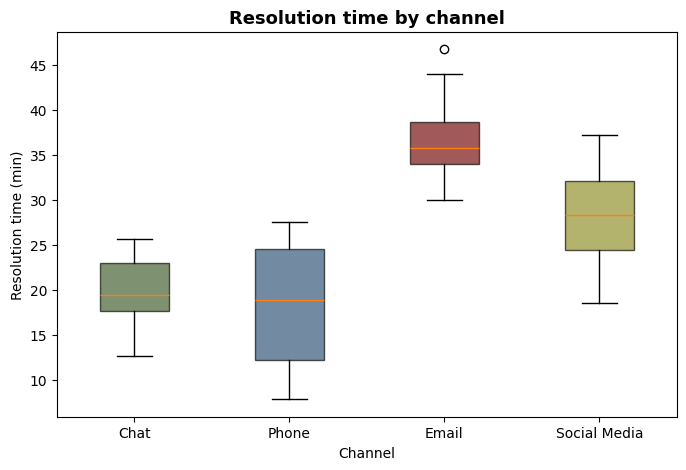

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
data_by_channel = [df.loc[df['channel'] == ch, 'resolution_time_min'].values for ch in channels]
bp = ax.boxplot(data_by_channel, tick_labels=channels, patch_artist=True)
for patch, c in zip(bp['boxes'], ['#395723', '#264D70', '#700000', '#8A8A20']):
    patch.set_facecolor(c); patch.set_alpha(0.65)
ax.set_title('Resolution time by channel', fontsize=13, fontweight='bold')
ax.set_xlabel('Channel'); ax.set_ylabel('Resolution time (min)')
plt.show()

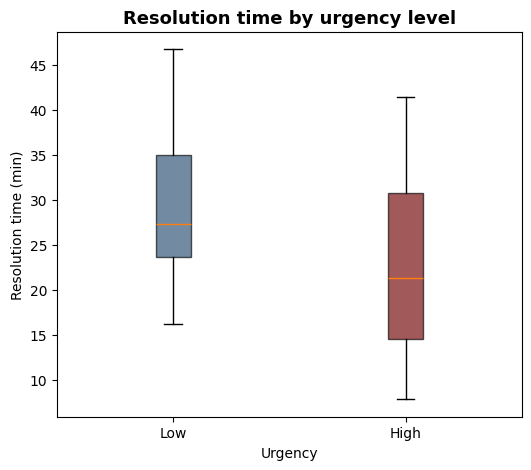

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
data_by_urg = [df.loc[df['urgency'] == u, 'resolution_time_min'].values for u in urgencies]
bp = ax.boxplot(data_by_urg, tick_labels=urgencies, patch_artist=True)
for patch, c in zip(bp['boxes'], ['#264D70', '#700000']):
    patch.set_facecolor(c); patch.set_alpha(0.65)
ax.set_title('Resolution time by urgency level', fontsize=13, fontweight='bold')
ax.set_xlabel('Urgency'); ax.set_ylabel('Resolution time (min)')
plt.show()

### The interaction plot

This is the key visual for a two-factor design: one line per urgency level, plotted across channels. **If the lines were parallel, there would be no interaction** — the effect of urgency would be the same "shift" for every channel. Non-parallel lines are a visual hint that an interaction may be present.

urgency         Low   High
channel                   
Chat          22.05  17.39
Phone         24.70  12.19
Email         37.88  34.78
Social Media  32.22  24.77


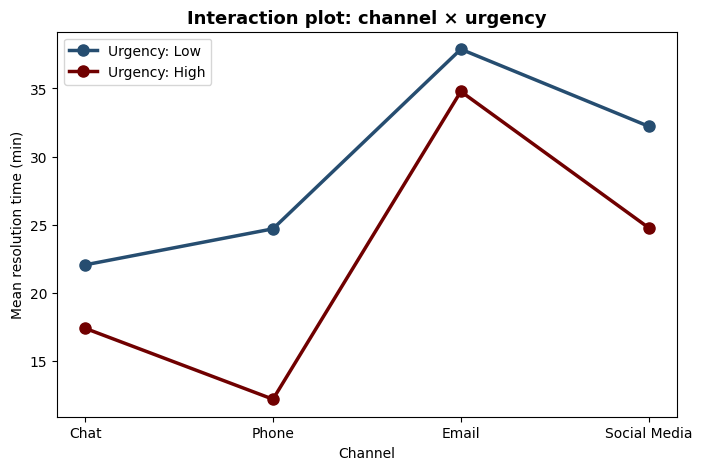

In [17]:
pivot = df.groupby(['channel', 'urgency'], observed=True)['resolution_time_min'].mean().unstack()
print(pivot.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for urgency, color in zip(urgencies, ['#264D70', '#700000']):
    ax.plot(pivot.index.astype(str), pivot[urgency], marker='o', linewidth=2.5,
            markersize=8, label=f'Urgency: {urgency}', color=color)
ax.set_xlabel('Channel'); ax.set_ylabel('Mean resolution time (min)')
ax.set_title('Interaction plot: channel × urgency', fontsize=13, fontweight='bold')
ax.legend()
plt.show()

The lines are clearly **not parallel**: Phone drops the most from Low → High urgency, while Email barely moves. This is exactly the pattern we built into the simulation — a strong visual hint that the interaction term will be significant.

## 4. Fitting the model & testing each hypothesis

**ANOVA is the same linear model as regression** (`ols`), just with categorical predictors. `C(channel):C(urgency)` adds the interaction term. One single fit gives us the F-test for all three effects at once.

In [18]:
model = ols('resolution_time_min ~ C(channel) + C(urgency) + C(channel):C(urgency)', data=df).fit()
anova_table = anova_lm(model, typ=2)
anova_table

,sum_sq,df,F,PR(>F)
C(channel),12248.677037,3.0,546.496064,2.933271e-103
C(urgency),2855.225251,1.0,382.172546,1.751434e-50
C(channel):C(urgency),756.528646,3.0,33.753843,4.581634e-18
Residual,1688.454375,226.0,NaN,NaN


### 4.1 'Channel' Effect
$$H_0: \mu_{Chat} = \mu_{Phone} = \mu_{Email} = \mu_{Social}$$
$$H_1: \text{at least one channel has a different mean resolution time}$$

- **p-value < 0.05 → reject H₀** (at least one channel has a different mean resolution time)
- **p-value ≥ 0.05 → fail to reject H₀** (no evidence that channels differ)

In [19]:
anova_table.loc['C(channel)', 'PR(>F)']

np.float64(2.9332707167051543e-103)

Channel means already range from **18.4 to 36.3 minutes**, a gap that large, on top of a design this big, points to a p-value well below 0.05.

- **Statistically:** we expect to reject H₀ — at least one channel has a significantly different mean.
- **In business terms:** the channel used **does** affect resolution time. Email is consistently the slowest channel.

### 4.2 'Urgency' Effect

$$H_0: \mu_{Low} = \mu_{High} \qquad H_1: \mu_{Low} \neq \mu_{High}$$

- **p-value < 0.05 → reject H₀** (Low and High urgency have different mean resolution times)
- **p-value ≥ 0.05 → fail to reject H₀** (no evidence that urgency affects resolution time)

In [20]:
anova_table.loc['C(urgency)', 'PR(>F)']

np.float64(1.7514340049813258e-50)

Urgency means (22.3 vs. 29.1 minutes) also differ enough that we expect to reject H₀ here as well.

- **Statistically:** we expect to reject H₀ — Low and High urgency tickets have significantly different mean resolution times.
- **In business terms:** urgent tickets **are** resolved faster overall — but as we'll see next, this headline is misleading on its own.

### 4.3 Interaction: channel × urgency

$$H_0: \text{the effect of channel is the same regardless of urgency (no interaction)}$$
$$H_1: \text{the effect of channel depends on the urgency level}$$

- **p-value < 0.05 → reject H₀** (the effect of channel depends on urgency, there is an interaction)
- **p-value ≥ 0.05 → fail to reject H₀** (no evidence of an interaction)

In [21]:
anova_table.loc['C(channel):C(urgency)', 'PR(>F)']

np.float64(4.581633696603527e-18)

The interaction plot in Section 3 already showed clearly non-parallel lines (Phone dropping much more than Email between Low and High urgency) — the visual signature of a real interaction.

- **Statistically:** we expect to reject H₀ — the urgency effect is **not** the same across channels.
- **In business terms:** the "urgent tickets are faster" effect is driven almost entirely by **Phone**. Reporting the urgency main effect alone would hide that Email customers get essentially **no benefit** from an urgent tag.

> **The most important business insight often lives in the interaction, not the main effects.** This is exactly why we always check it before trusting a main effect in isolation.

## 5. Checking assumptions

Before trusting the F-test results, we need to check that the model's assumptions actually hold.  
We'll work with the **residuals**, the part of each observation the model *couldn't* explain and the model's **fitted values** its predicted mean for each group.

### Quick sanity check: manual calculation vs. `model.resid`

Since we included the interaction term, this model has one parameter for every channel × urgency combination, so its prediction for any ticket is simply the average of its own group. That means we can double-check `model.resid` by computing residuals ourselves, and the two should match exactly.

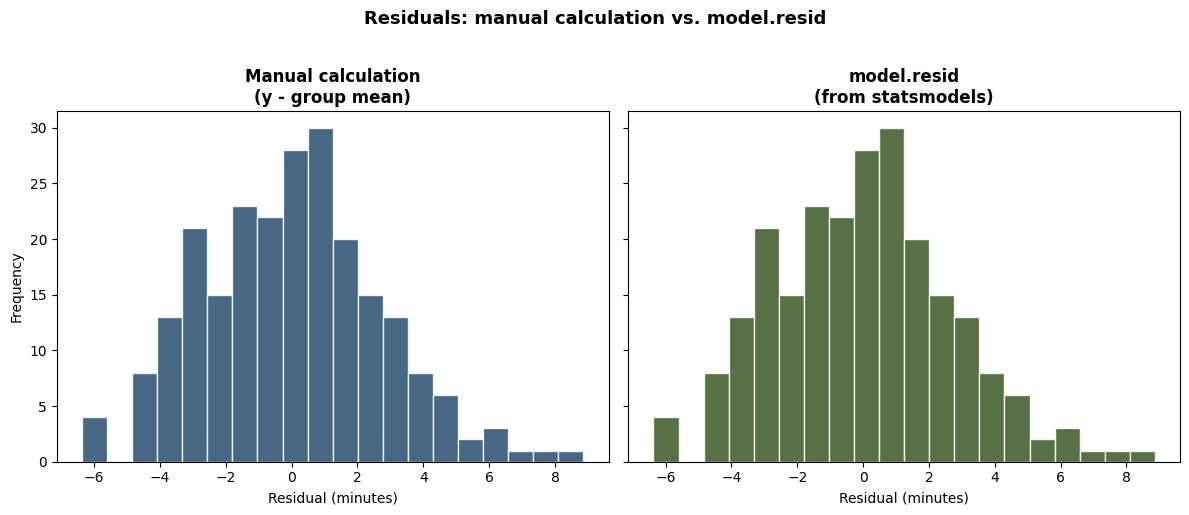

Max absolute difference: 2.3092638912203256e-14


In [22]:
# Manual calculation: residual = observed value - its own group's mean
manual_cell_mean = df.groupby(['channel', 'urgency'], observed=True)['resolution_time_min'].transform('mean')
manual_residual = df['resolution_time_min'] - manual_cell_mean

# Direct from statsmodels
model_residual = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

axes[0].hist(manual_residual, bins=20, edgecolor='white', color='#264D70', alpha=0.85)
axes[0].set_title('Manual calculation\n(y - group mean)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Residual (minutes)'); axes[0].set_ylabel('Frequency')

axes[1].hist(model_residual, bins=20, edgecolor='white', color='#395723', alpha=0.85)
axes[1].set_title('model.resid\n(from statsmodels)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual (minutes)')

fig.suptitle('Residuals: manual calculation vs. model.resid', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Max absolute difference:", (manual_residual.values - model_residual.values).__abs__().max())

### Normality: Shapiro-Wilk test

$$H_0: \text{the residuals are normally distributed}$$
$$H_1: \text{the residuals are not normally distributed}$$

**Decision rule** (α = 0.05):

- **p-value < 0.05 → reject H₀** (residuals are not normal — the assumption is violated)
- **p-value ≥ 0.05 → fail to reject H₀** (no evidence against normality — the assumption holds)

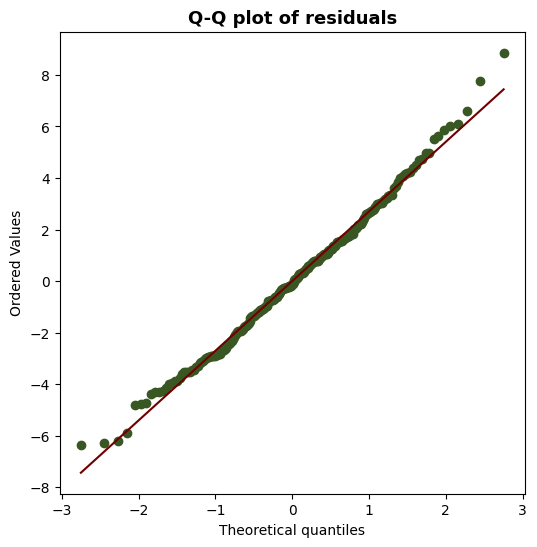

Shapiro-Wilk test: W = 0.9932, p-value = 0.3597


In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(model_residual, dist='norm', plot=ax)
ax.get_lines()[0].set_markerfacecolor('#395723'); ax.get_lines()[0].set_markeredgecolor('#395723')
ax.get_lines()[1].set_color('#700000')
ax.set_title('Q-Q plot of residuals', fontsize=13, fontweight='bold')
plt.show()

stat_sw, p_norm = stats.shapiro(model_residual)
print(f"Shapiro-Wilk test: W = {stat_sw:.4f}, p-value = {p_norm:.4g}")

Both the histogram and the Q-Q plot look reasonably bell shaped, with no obvious skew. The Shapiro-Wilk p-value (0.3597) confirms it: **we fail to reject normality**, consistent with residuals that behave like random noise around each group mean.

### Homoscedasticity: Levene's test

$$H_0: \text{all groups have equal variance}$$
$$H_1: \text{at least one group has a different variance}$$

**Decision rule** (α = 0.05):

- **p-value < 0.05 → reject H₀** (variances are not equal — the assumption is violated)
- **p-value ≥ 0.05 → fail to reject H₀** (no evidence against equal variances — the assumption holds)

In [26]:
stat_manual, p_manual = stats.levene(
    df['resolution_time_min'][(df['channel'] == 'Chat') & (df['urgency'] == 'Low')],
    df['resolution_time_min'][(df['channel'] == 'Chat') & (df['urgency'] == 'High')],
    df['resolution_time_min'][(df['channel'] == 'Phone') & (df['urgency'] == 'Low')],
    df['resolution_time_min'][(df['channel'] == 'Phone') & (df['urgency'] == 'High')],
    df['resolution_time_min'][(df['channel'] == 'Email') & (df['urgency'] == 'Low')],
    df['resolution_time_min'][(df['channel'] == 'Email') & (df['urgency'] == 'High')],
    df['resolution_time_min'][(df['channel'] == 'Social Media') & (df['urgency'] == 'Low')],
    df['resolution_time_min'][(df['channel'] == 'Social Media') & (df['urgency'] == 'High')]
)
stat_manual, p_manual

(np.float64(0.9918549383484747), np.float64(0.43792263234871665))

Expect a fairly even spread across all fitted values, with no funnel shape. Levene's test (statistic = 0.9919, p-value = 0.4379) confirms it, **we fail to reject homoscedasticity**.

**Both assumptions hold directly on the raw `resolution_time_min` scale, no transformation needed.** We can go straight to the ANOVA table and Tukey HSD using the original minutes, which also keeps every result easy to communicate to a business audience.

> Not all datasets are this well behaved, duration/money variables are often right skewed with variance that grows with the mean, in which case a log transform is the standard fix.

## 6. Post-hoc comparisons (Tukey HSD)

Since we expect the **interaction** to be significant, comparing only the 4 channel means (ignoring urgency) or the 2 urgency means (ignoring channel) would hide the real story. The right move is to compare all **8 channel × urgency combinations** directly.

### Post-hoc comparisons — Tukey HSD

For each pair of groups (i, j) among the 8 channel × urgency combinations:

$$H_0: \mu_i = \mu_j$$
$$H_1: \mu_i \neq \mu_j$$

**Decision rule** (α = 0.05):

- **p-adj < 0.05 → reject H₀** (this specific pair has significantly different means)
- **p-adj ≥ 0.05 → fail to reject H₀** (no evidence that this pair differs)


> Run this in your own environment (needs `statsmodels`).

In [29]:
df['channel_urgency'] = df['channel'].astype(str) + ' | ' + df['urgency'].astype(str)

tukey = pairwise_tukeyhsd(
    endog=df['resolution_time_min'],
    groups=df['channel_urgency'],
    alpha=0.05
)
print(tukey)

              Multiple Comparison of Means - Tukey HSD, FWER=0.05               
       group1              group2       meandiff p-adj   lower    upper   reject
--------------------------------------------------------------------------------
        Chat | High          Chat | Low   4.6556    0.0   2.4372    6.874   True
        Chat | High        Email | High  17.3835    0.0   15.147  19.6199   True
        Chat | High         Email | Low  20.4833    0.0  18.2468  22.7197   True
        Chat | High        Phone | High  -5.2066    0.0   -7.425  -2.9882   True
        Chat | High         Phone | Low   7.3004    0.0   5.0819   9.5188   True
        Chat | High Social Media | High   7.3753    0.0   5.1569   9.5937   True
        Chat | High  Social Media | Low  14.8236    0.0  12.5872  17.0601   True
         Chat | Low        Email | High  12.7279    0.0  10.5501  14.9057   True
         Chat | Low         Email | Low  15.8277    0.0  13.6499  18.0055   True
         Chat | Low        P

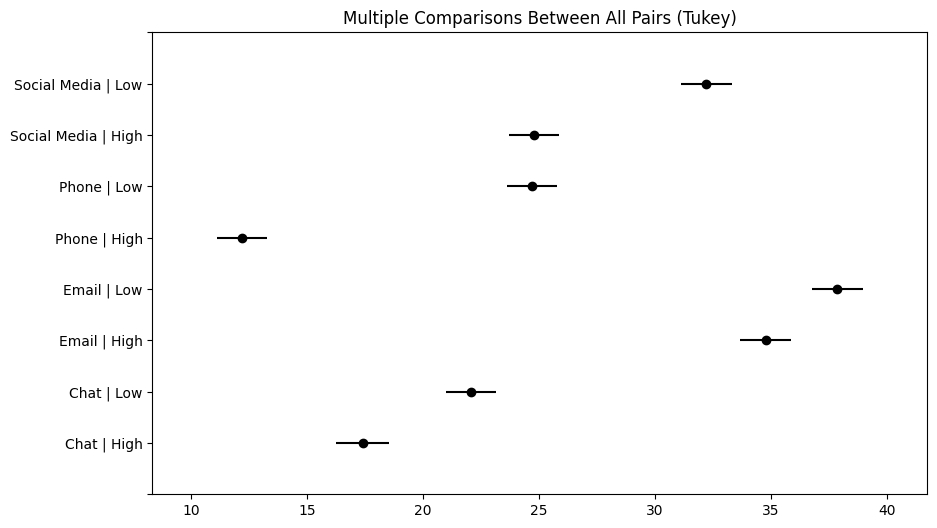

In [30]:
tukey.plot_simultaneous()
plt.show()

Look specifically at rows comparing **Phone | Low** vs **Phone | High** (expect a large, significant gap) against **Email | Low** vs **Email | High** (expect little to no significant difference), that contrast *is* the interaction, made concrete at the pairwise level.

## 7. Business conclusions

Putting the statistics back into the language the Operations team actually needs:

1. **Channel matters.** Email tickets take roughly **36 minutes** on average, noticeably longer than Chat (**20 min**) or Phone (**18 min**).

2. **"Urgent tickets are resolved faster" is true, but misleading if reported alone.** The speed up is driven almost entirely by **Phone**, where an escalation process cuts resolution time by about **13 minutes** on high urgency. **Email only drops about 3 minutes**, essentially no meaningful speed up.

3. **Statistical note:** we checked normality and homoscedasticity directly on the raw `resolution_time_min` data, both held up, so no transformation was needed for these results to be trustworthy.

## 8. Recommendations for the decision-maker

The statistics tell us *what* is happening; here's what Operations could actually **do** about it.

| # | Recommendation | Why | Priority |
|---|---|---|---|
| 1 | Design an escalation / fast-track path for **urgent Email tickets**, similar to the one Phone already has | Email gets zero speed-up from being marked urgent — the one channel where "urgent" currently means nothing | **High** |
| 2 | Investigate root causes of Email's overall slowness (staffing levels, templated responses, routing rules) | Email is the slowest channel on average, regardless of urgency | **High** |
| 3 | Study Phone's escalation process as a **template** to replicate in other channels | It's the single biggest driver of the urgency effect — worth understanding *why* it works so well | Medium |
| 4 | Re-evaluate how "urgency" is reported in dashboards | A single blended "urgent tickets are X% faster" metric hides that this is basically a Phone-only effect | Medium |
| 5 | Re-run this analysis quarterly with fresh data | Channel mix and staffing change over time; a one-time analysis can go stale | Low |

**Suggested next step:** pilot an Email fast-track for high-urgency tickets in one region/team for 4–6 weeks, then re-run this same two-factor ANOVA on the pilot data to confirm the interaction gap has closed.